# 1. Data collection: what can we actually get for Burundi?

**Imbuto AI series.** This notebook asks a simple question before any modelling: which real, open data exists for Burundi, and how much can we trust it?

The concept note lists many sources. Some, such as IGEBU stations, need partnerships. A project should start with what is open today, show value, and use that to earn access to the rest.

Run `make data` once first. Each source is downloaded unchanged and recorded in a manifest.

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["IMBUTO_ROOT"] = str(ROOT)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 10})
GREEN, GREY, BROWN = "#1f6e3f", "#9aa89f", "#8c510a"

## The sources and their manifest

Every download records its URL, checksum, size and time. Six months from now, you can still say exactly which bytes produced a result.

In [2]:
from imbuto.lakehouse.sources import SOURCES
manifest = json.loads((ROOT / "data/bronze/_manifest.json").read_text())
pd.DataFrame(manifest).T[["bytes", "fetched_at"]].assign(MB=lambda d: (d.bytes.astype(float) / 1e6).round(2))

ModuleNotFoundError: No module named 'imbuto'

## Rainfall: CHIRPS

CHIRPS blends satellite and rain-gauge data at about 5 km, monthly from 1981. It suits a country with few public stations. Downloading the world would be gigabytes; asking for a Burundi box is 4 MB. **Ask servers for less. It is the first low-bandwidth decision in the project.**

In [3]:
from scipy.io import netcdf_file
with netcdf_file(ROOT / "data/bronze/chirps_monthly.nc", mmap=False) as nc:
    grid = nc.variables["precipitation"][:].astype(float); t = nc.variables["T"][:]
grid[grid < -1000] = np.nan
print("shape (months, lat, lon):", grid.shape)
print("first month:", f"{1960 + int(t[0]) // 12}-{int(t[0]) % 12 + 1:02d}", "| last month:", f"{1960 + int(t[-1]) // 12}-{int(t[-1]) % 12 + 1:02d}")

shape (months, lat, lon): (549, 45, 40)
first month: 1981-01 | last month: 2026-09


**Sanity check before trusting it.** Burundi has a known dry season from June to August. If the data disagrees, the problem is in the data or in our reading of it.

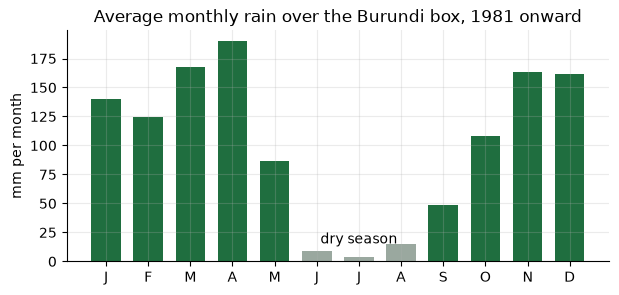

In [4]:
months = pd.Series([(1 + int(v) % 12) for v in t])
means = pd.Series(np.nanmean(grid, axis=(1, 2))).groupby(months).mean()
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(means.index, means.values, color=[GREY if m in (6, 7, 8) else GREEN for m in means.index], width=.7)
ax.set(title="Average monthly rain over the Burundi box, 1981 onward", ylabel="mm per month",
       xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"))
ax.annotate("dry season", (7, means[7] + 12), ha="center"); plt.show()

## Places: 119 communes on a map, 42 in law

Here is a real local trap. Burundi moved from 18 provinces and 119 communes to **5 provinces and 42 communes** in 2025. Open boundary files still show the old 119. We could not find open geometry for the new 42.

So we use the old polygons for spatial work and group them into the current five provinces. This is approximate for Rumonge and Muramvya, which were split. A partner with the official boundaries would fix this quickly, which is exactly why the concept note asks for partners.

In [5]:
from imbuto.lakehouse.build import build_communes, NEW_PROVINCE
communes = build_communes(ROOT / "data/bronze")
print("Communes:", len(communes), "| Current provinces:", communes.province.nunique())
print("Duplicate names:", communes.commune[communes.commune.duplicated()].tolist(), "(so we use IDs, not names)")
communes.groupby("province").commune.count().rename("communes in the map").to_frame()

Communes: 119 | Current provinces: 5
Duplicate names: ['Butaganzwa'] (so we use IDs, not names)


,communes in the map
province,
Buhumuza,19
Bujumbura,23
Burunga,23
Butanyerera,25
Gitega,29


## Prices: WFP market data

Each row is a monthly price at a named market, published openly through HDX. Note the fields `priceflag` and `pricetype`: a careful reader keeps actual retail prices and does not mix them with wholesale.

127,576 retail rows, 73 markets, 2003-01 to 2026-09


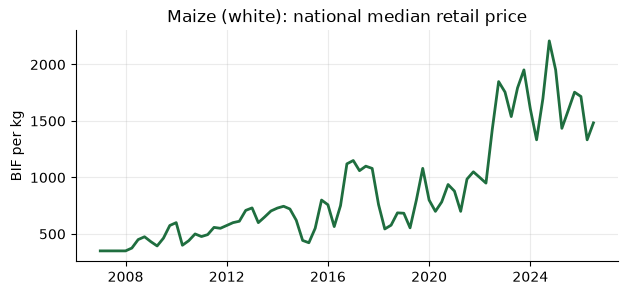

In [6]:
prices = pd.read_csv(ROOT / "data/bronze/wfp_food_prices_bdi.csv", low_memory=False)
prices = prices[prices.pricetype.eq("Retail") & prices.currency.eq("BIF")].assign(date=lambda d: pd.to_datetime(d.date))
print(f"{len(prices):,} retail rows, {prices.market.nunique()} markets, {prices.date.min():%Y-%m} to {prices.date.max():%Y-%m}")
maize = prices[prices.commodity.eq("Maize (white)")].groupby(pd.Grouper(key="date", freq="QS")).price.median().dropna()
fig, ax = plt.subplots(figsize=(7, 3)); ax.plot(maize.index, maize.values, color=GREEN, lw=2)
ax.set(title="Maize (white): national median retail price", ylabel="BIF per kg"); plt.show()

The curve is a reminder of why the note lists economic strain as a pressure. Nominal prices have risen steeply, so any "cheap" or "expensive" advice must use recent months only.

## Climate drivers: El Nino and the Indian Ocean Dipole

NOAA publishes both. They matter here because they shape East African rains. They are also a good lesson in **data leakage**: an index for September is not published on the first of October, so a forecast made then must not use it.

In [7]:
from imbuto.lakehouse.build import parse_oni, parse_dmi
oni = parse_oni(ROOT / "data/bronze/oni.txt"); print(oni.tail(4).to_string(index=False))

     month  oni
2026-06-01 0.95
2026-07-01 1.39
2026-08-01 1.80
2026-09-01 2.16


## Images: the iBean dataset

Bean leaf photos collected in Uganda by Makerere University's AI Lab, under an MIT licence. It is East African, which is better than a greenhouse dataset, but **it is not Burundian**. A model trained here earns no claims about Burundi until it is tested on local photos.

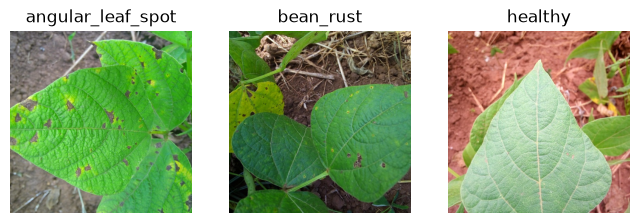

{0: 345, 1: 348, 2: 341}


In [8]:
import io
from PIL import Image
beans = pd.read_parquet(ROOT / "data/bronze/beans/train.parquet")
names = ["angular_leaf_spot", "bean_rust", "healthy"]
fig, axes = plt.subplots(1, 3, figsize=(8, 2.9))
for label, ax in enumerate(axes):
    row = beans[beans.labels == label].iloc[3]
    ax.imshow(Image.open(io.BytesIO(row.image["bytes"]))); ax.set_title(names[label]); ax.axis("off")
plt.show(); print(beans.labels.value_counts().sort_index().to_dict())

## What is missing

| Wanted | Status | Who could help |
| --- | --- | --- |
| Kirundi speech | Not collected | University of Burundi, community data drives |
| Official 42-commune boundaries | Not found openly | Government, OCHA |
| Station rainfall and lake levels | Not open | IGEBU |
| Commune-level food-security history | Not open | IPC partners, WFP |
| Burundian crop photos | Not collected | Farmers, ISABU, field partners |

**Next:** notebook 2 turns these raw files into tables that models can use.